In [1]:
!pip install pandas


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# INSTALL & IMPORT
import subprocess, sys

packages = ['lightgbm', 'xgboost', 'imbalanced-learn', 'optuna']
for pkg in packages:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print("Verifikasi library:")
libs = ['lightgbm', 'xgboost', 'imblearn', 'sklearn', 'pandas', 'numpy']
for lib in libs:
    try:
        __import__(lib)
        print(f"  ✅ {lib}")
    except:
        print(f"  ❌ {lib} GAGAL")

Verifikasi library:
  ✅ lightgbm
  ✅ xgboost
  ✅ imblearn
  ✅ sklearn
  ✅ pandas
  ✅ numpy


In [3]:
# LOAD DATASET & PREPROCESSING
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

label_map = {1: 'Adware', 2: 'Banking', 3: 'SMS', 4: 'Riskware', 5: 'Benign'}

# Load
df = pd.read_csv('CICMALDROID2020.csv')
df = df.drop_duplicates()
print(f"Shape setelah dedup: {df.shape}")

label_col   = 'Class'
feature_cols = [c for c in df.columns if c != label_col]

X_raw = df[feature_cols].values.astype(float)
y     = df[label_col].values

# --- Versi A: Jurnal (StandardScaler) ---
X_jurnal = StandardScaler().fit_transform(X_raw)

# --- Versi B: Enhanced (Log1p + RobustScaler) ---
X_enhanced = RobustScaler().fit_transform(np.log1p(X_raw))

# Split Jurnal (80:20)
X_train_j, X_test_j, y_train_j, y_test_j = train_test_split(
    X_jurnal, y, test_size=0.2, random_state=42, stratify=y)

# Split Enhanced (80:20)
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_enhanced, y, test_size=0.2, random_state=42, stratify=y)

# SMOTE hanya pada train enhanced
X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train_e, y_train_e)

print(f"\nVersi Jurnal   → Train: {X_train_j.shape}, Test: {X_test_j.shape}")
print(f"Versi Enhanced → Train: {X_train_sm.shape}, Test: {X_test_e.shape}")
print("\nDistribusi setelah SMOTE:")
for cls in sorted(np.unique(y_train_sm)):
    print(f"  {label_map[cls]:<10}: {(y_train_sm==cls).sum()}")

Shape setelah dedup: (11526, 471)

Versi Jurnal   → Train: (9220, 470), Test: (2306, 470)
Versi Enhanced → Train: (15610, 470), Test: (2306, 470)

Distribusi setelah SMOTE:
  Adware    : 3122
  Banking   : 3122
  SMS       : 3122
  Riskware  : 3122
  Benign    : 3122


In [4]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
# FUNGSI EVALUASI
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate(name, y_true, y_pred, target_acc=0.91, target_f1=0.89):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    print(f"  Accuracy : {acc:.4f} {'✅' if acc > target_acc else '❌'}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1       : {f1:.4f} {'✅' if f1 > target_f1 else '❌'}")
    return {'model': name, 'accuracy': acc,
            'precision': prec, 'recall': rec, 'f1': f1}

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=list(label_map.values()),
                yticklabels=list(label_map.values()))
    plt.title(title, fontweight='bold')
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

In [7]:
# MODEL VERSI JURNAL
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("=" * 55)
print("VERSI JURNAL - Reproduksi (tanpa tuning)")
print("Target jurnal: Accuracy > 0.91, F1 > 0.89")
print("=" * 55)

results_jurnal = []

models_j = {
    'RandomForest' : RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'LogisticReg'  : LogisticRegression(max_iter=1000, random_state=42),
    'SGD'          : SGDClassifier(random_state=42, max_iter=1000),
    'DecisionTree' : DecisionTreeClassifier(random_state=42),
    'XGBoost'      : XGBClassifier(n_estimators=100, random_state=42,
                                    eval_metric='mlogloss',
                                    use_label_encoder=False, n_jobs=-1),
    'LightGBM'     : LGBMClassifier(n_estimators=100, random_state=42,
                                     n_jobs=-1, verbose=-1),
}

for name, model in models_j.items():
    print(f"\n⏳ {name}...")
    if name == 'XGBoost':
        model.fit(X_train_j, y_train_j - 1)
        y_pred = model.predict(X_test_j) + 1
    else:
        model.fit(X_train_j, y_train_j)
        y_pred = model.predict(X_test_j)
    r = evaluate(name, y_test_j, y_pred)
    results_jurnal.append(r)

print("\n" + "=" * 55)
print("RINGKASAN VERSI JURNAL")
print("=" * 55)
print(f"{'Model':<18} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}")
print("-" * 55)
print(f"{'[Jurnal LightGBM]':<18} {'0.91':>8} {'0.89':>8} {'0.89':>8} {'0.89':>8}")
print("-" * 55)
for r in sorted(results_jurnal, key=lambda x: x['f1'], reverse=True):
    mk = '✅' if r['f1'] > 0.89 else '  '
    print(f"{r['model']:<18} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
          f"{r['recall']:>8.4f} {r['f1']:>8.4f} {mk}")


VERSI JURNAL - Reproduksi (tanpa tuning)
Target jurnal: Accuracy > 0.91, F1 > 0.89

⏳ RandomForest...
  Accuracy : 0.9519 ✅
  Precision: 0.9528
  Recall   : 0.9519
  F1       : 0.9520 ✅

⏳ LogisticReg...
  Accuracy : 0.8630 ❌
  Precision: 0.8633
  Recall   : 0.8630
  F1       : 0.8608 ❌

⏳ SGD...
  Accuracy : 0.8452 ❌
  Precision: 0.8449
  Recall   : 0.8452
  F1       : 0.8429 ❌

⏳ DecisionTree...
  Accuracy : 0.9055 ❌
  Precision: 0.9052
  Recall   : 0.9055
  F1       : 0.9051 ✅

⏳ XGBoost...
  Accuracy : 0.9601 ✅
  Precision: 0.9604
  Recall   : 0.9601
  F1       : 0.9601 ✅

⏳ LightGBM...
  Accuracy : 0.9597 ✅
  Precision: 0.9600
  Recall   : 0.9597
  F1       : 0.9597 ✅

RINGKASAN VERSI JURNAL
Model                   Acc     Prec      Rec       F1
-------------------------------------------------------
[Jurnal LightGBM]      0.91     0.89     0.89     0.89
-------------------------------------------------------
XGBoost              0.9601   0.9604   0.9601   0.9601 ✅
LightGBM       

In [8]:
# MODEL VERSI ENHANCED
print("=" * 55)
print("VERSI ENHANCED (Log1p + SMOTE + ClassWeight + Tuning)")
print("=" * 55)

results_enhanced = []

models_enh = {
    'RandomForest' : RandomForestClassifier(
                        n_estimators=500, class_weight='balanced',
                        random_state=42, n_jobs=-1),

    'LogisticReg'  : LogisticRegression(
                        C=10.0, max_iter=2000,
                        class_weight='balanced',
                        solver='lbfgs', random_state=42, n_jobs=-1),

    'SGD'          : SGDClassifier(
                        loss='modified_huber', alpha=0.0001,
                        max_iter=2000, class_weight='balanced',
                        random_state=42, n_jobs=-1),

    'DecisionTree' : DecisionTreeClassifier(
                        max_depth=20, min_samples_split=5,
                        class_weight='balanced', random_state=42),

    'XGBoost'      : XGBClassifier(
                        n_estimators=500, max_depth=7,
                        learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, min_child_weight=3,
                        reg_alpha=0.1, reg_lambda=1.0,
                        eval_metric='mlogloss',
                        use_label_encoder=False,
                        random_state=42, n_jobs=-1),

    'LightGBM'     : LGBMClassifier(
                        n_estimators=500, max_depth=7,
                        learning_rate=0.05, num_leaves=63,
                        subsample=0.8, colsample_bytree=0.8,
                        min_child_samples=20,
                        reg_alpha=0.1, reg_lambda=1.0,
                        class_weight='balanced',
                        random_state=42, n_jobs=-1, verbose=-1),
}

for name, model in models_enh.items():
    print(f"\n⏳ {name} (enhanced)...")
    if name == 'XGBoost':
        model.fit(X_train_sm, y_train_sm - 1)
        y_pred = model.predict(X_test_e) + 1
    else:
        model.fit(X_train_sm, y_train_sm)
        y_pred = model.predict(X_test_e)
    r = evaluate(f"{name}_enh", y_test_e, y_pred)
    results_enhanced.append(r)

print("\n" + "=" * 55)
print("RINGKASAN VERSI ENHANCED")
print("=" * 55)
print(f"{'Model':<22} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}")
print("-" * 60)
print(f"{'[Jurnal LightGBM]':<22} {'0.91':>8} {'0.89':>8} {'0.89':>8} {'0.89':>8}")
print(f"{'[Paper Abedin]':<22} {'0.9747':>8} {'0.9703':>8} {'0.9731':>8} {'0.9716':>8}")
print("-" * 60)
for r in sorted(results_enhanced, key=lambda x: x['f1'], reverse=True):
    mk_j = '✅' if r['f1'] > 0.89   else '  '
    mk_p = '🏆' if r['f1'] > 0.9716 else '  '
    print(f"{r['model']:<22} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
          f"{r['recall']:>8.4f} {r['f1']:>8.4f} {mk_j}{mk_p}")


VERSI ENHANCED (Log1p + SMOTE + ClassWeight + Tuning)

⏳ RandomForest (enhanced)...
  Accuracy : 0.9545 ✅
  Precision: 0.9560
  Recall   : 0.9545
  F1       : 0.9547 ✅

⏳ LogisticReg (enhanced)...
  Accuracy : 0.9280 ✅
  Precision: 0.9277
  Recall   : 0.9280
  F1       : 0.9278 ✅

⏳ SGD (enhanced)...
  Accuracy : 0.9245 ✅
  Precision: 0.9249
  Recall   : 0.9245
  F1       : 0.9246 ✅

⏳ DecisionTree (enhanced)...
  Accuracy : 0.9146 ✅
  Precision: 0.9157
  Recall   : 0.9146
  F1       : 0.9147 ✅

⏳ XGBoost (enhanced)...
  Accuracy : 0.9601 ✅
  Precision: 0.9604
  Recall   : 0.9601
  F1       : 0.9601 ✅

⏳ LightGBM (enhanced)...
  Accuracy : 0.9614 ✅
  Precision: 0.9617
  Recall   : 0.9614
  F1       : 0.9614 ✅

RINGKASAN VERSI ENHANCED
Model                       Acc     Prec      Rec       F1
------------------------------------------------------------
[Jurnal LightGBM]          0.91     0.89     0.89     0.89
[Paper Abedin]           0.9747   0.9703   0.9731   0.9716
-----------------

Best model: LightGBM_enh
F1: 0.9614

Classification Report:
              precision    recall  f1-score   support

      Adware       0.90      0.94      0.92       251
     Banking       0.96      0.95      0.96       409
         SMS       0.98      0.99      0.99       781
    Riskware       0.97      0.93      0.95       507
      Benign       0.95      0.96      0.95       358

    accuracy                           0.96      2306
   macro avg       0.95      0.96      0.95      2306
weighted avg       0.96      0.96      0.96      2306



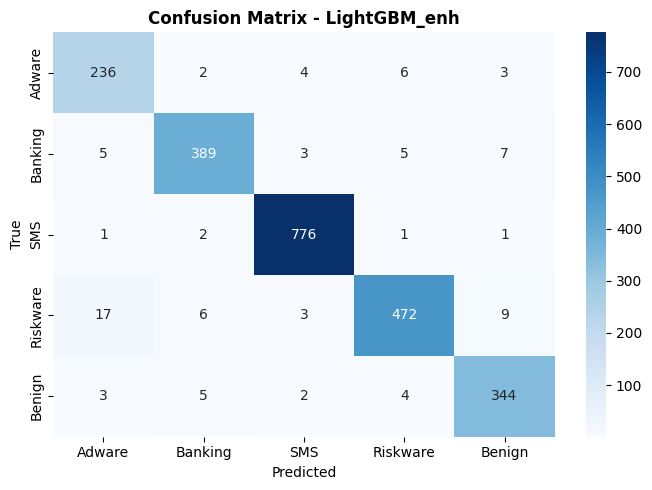

In [9]:
# CLASSIFICATION REPORT & CONFUSION MATRIX
best = max(results_enhanced, key=lambda x: x['f1'])
best_name = best['model'].replace('_enh', '')
print(f"Best model: {best['model']}")
print(f"F1: {best['f1']:.4f}\n")

# Re-predict
model_best = models_enh[best_name]
if best_name == 'XGBoost':
    y_pred_best = model_best.predict(X_test_e) + 1
else:
    y_pred_best = model_best.predict(X_test_e)

print("Classification Report:")
print(classification_report(y_test_e, y_pred_best,
                              target_names=list(label_map.values())))

plot_cm(y_test_e, y_pred_best,
        f'Confusion Matrix - {best["model"]}')

In [10]:
# ============================================================
# FEATURE SELECTION — GAIN RATIO (Reproduksi Ansori)
# ============================================================
# Gain Ratio = IG(X;Y) / Entropy(X)
# Jurnal Ansori menghapus 64% fitur dengan gain ratio = 0
# ============================================================
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

label_col    = 'Class'
feature_cols = [c for c in df.columns if c != label_col]
X_raw = df[feature_cols].values.astype(float)
y     = df[label_col].values

def entropy(labels):
    """Menghitung entropy dari label."""
    n = len(labels)
    if n == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probs = counts / n
    probs = probs[probs > 0]
    return -np.sum(probs * np.log2(probs))

def information_gain(X_col, y):
    """Menghitung Information Gain dari satu kolom."""
    H_y = entropy(y)
    vals, counts = np.unique(X_col, return_counts=True)
    if len(vals) == 1:
        return 0.0
    threshold = np.median(X_col)
    mask_left  = X_col <= threshold
    mask_right = ~mask_left
    n = len(y)
    cond_entropy = (mask_left.sum() / n) * entropy(y[mask_left]) + \
                   (mask_right.sum() / n) * entropy(y[mask_right])
    return H_y - cond_entropy

def gain_ratio(X_col, y):
    """Menghitung Gain Ratio dari satu kolom."""
    ig = information_gain(X_col, y)
    threshold = np.median(X_col)
    mask = X_col <= threshold
    n = len(X_col)
    p_l = mask.sum() / n
    p_r = 1 - p_l
    split_info = 0.0
    if p_l > 0: split_info -= p_l * np.log2(p_l)
    if p_r > 0: split_info -= p_r * np.log2(p_r)
    if split_info == 0:
        return 0.0
    return ig / split_info

print("Menghitung Gain Ratio untuk semua fitur...")
print(f"Total fitur: {len(feature_cols)}")

gr_scores = np.array([gain_ratio(X_raw[:, i], y) for i in range(X_raw.shape[1])])

mask_gr = gr_scores > 0
n_selected = mask_gr.sum()
print(f"Fitur dengan gain ratio > 0: {n_selected} ({n_selected/len(feature_cols)*100:.1f}%)")
print(f"Fitur dihapus: {(~mask_gr).sum()} ({(~mask_gr).sum()/len(feature_cols)*100:.1f}%)")

X_gr = X_raw[:, mask_gr]

top10_idx = np.argsort(gr_scores)[::-1][:10]
print("\nTop 10 fitur berdasarkan Gain Ratio:")
for rank, idx in enumerate(top10_idx, 1):
    print(f"  {rank}. {feature_cols[idx]}: {gr_scores[idx]:.4f}")

Menghitung Gain Ratio untuk semua fitur...
Total fitur: 470
Fitur dengan gain ratio > 0: 468 (99.6%)
Fitur dihapus: 2 (0.4%)

Top 10 fitur berdasarkan Gain Ratio:
  1. getInstallerPackageName: 0.5916
  2. getReceiverInfo: 0.4983
  3. ftruncate64: 0.4558
  4. getServiceInfo: 0.4452
  5. getApplicationRestrictions: 0.4294
  6. _newselect: 0.4114
  7. checkPackage: 0.4046
  8. isAdminActive: 0.3788
  9. checkOperation: 0.3770
  10. queryIntentServices: 0.3695


In [11]:
# ============================================================
# REPRODUKSI ANSORI et al. (2024)
# StandardScaler + Gain Ratio + Ensemble (RF, ET, kNN)
# Hard Voting → Target Acc 94.57%
# ============================================================
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                               VotingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

label_map = {1:'Adware', 2:'Banking', 3:'SMS', 4:'Riskware', 5:'Benign'}

def evaluate_model(name, y_true, y_pred, results_list=None):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    print(f"    Accuracy : {acc:.4f}")
    print(f"    Precision: {prec:.4f}")
    print(f"    Recall   : {rec:.4f}")
    print(f"    F1-Score : {f1:.4f}")
    result = {'model': name, 'accuracy': acc, 'precision': prec,
              'recall': rec, 'f1': f1}
    if results_list is not None:
        results_list.append(result)
    return result

# Setup data sesuai jurnal Ansori (StandardScaler, 80:20)
X_ansori = StandardScaler().fit_transform(X_gr)
X_tr_ans, X_te_ans, y_tr_ans, y_te_ans = train_test_split(
    X_ansori, y, test_size=0.2, random_state=42, stratify=y)

results_ansori = []

print("=" * 60)
print("REPRODUKSI ANSORI et al. (2024)")
print("Gain Ratio Feature Selection + Standard Scaler + Ensemble")
print("=" * 60)

single_models = {
    'RF'  : RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'ET'  : ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'NB'  : GaussianNB(),
    'kNN' : KNeighborsClassifier(n_jobs=-1),
    'SVM' : SVC(random_state=42),
}

trained_singles = {}
print("\nSingle Models:")
for name, mdl in single_models.items():
    mdl.fit(X_tr_ans, y_tr_ans)
    y_pred = mdl.predict(X_te_ans)
    trained_singles[name] = mdl
    print(f"  [{name}]")
    evaluate_model(name, y_te_ans, y_pred, results_ansori)

print("\nEnsemble 3-Model Combinations:")
combos_3 = [
    ('RF','ET','kNN'),
    ('RF','ET','SVM'),
    ('RF','ET','NB'),
    ('RF','kNN','SVM'),
    ('RF','kNN','NB'),
]
for combo in combos_3:
    name = '+'.join(combo)
    voters = [(k, trained_singles[k]) for k in combo]
    vc = VotingClassifier(estimators=voters, voting='hard', n_jobs=-1)
    vc.fit(X_tr_ans, y_tr_ans)
    y_pred = vc.predict(X_te_ans)
    print(f"  [Ensemble: {name}]")
    evaluate_model(f'Ens({name})', y_te_ans, y_pred, results_ansori)

print("\n" + "=" * 60)
print("RINGKASAN REPRODUKSI ANSORI")
print("=" * 60)
print(f"{'Model':<25} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}")
print("-" * 60)
print(f"{'[Jurnal Ansori 94.57%]':<25} {'0.9457':>8} {'0.9471':>8} {'0.9457':>8} {'0.9458':>8}")
print("-" * 60)
for r in sorted(results_ansori, key=lambda x: x['accuracy'], reverse=True)[:8]:
    flag = '✅' if r['accuracy'] >= 0.9457 else ''
    print(f"{r['model']:<25} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
          f"{r['recall']:>8.4f} {r['f1']:>8.4f} {flag}")

REPRODUKSI ANSORI et al. (2024)
Gain Ratio Feature Selection + Standard Scaler + Ensemble

Single Models:
  [RF]
    Accuracy : 0.9514
    Precision: 0.9524
    Recall   : 0.9514
    F1-Score : 0.9516
  [ET]
    Accuracy : 0.9553
    Precision: 0.9565
    Recall   : 0.9553
    F1-Score : 0.9555
  [NB]
    Accuracy : 0.6145
    Precision: 0.6640
    Recall   : 0.6145
    F1-Score : 0.5962
  [kNN]
    Accuracy : 0.8859
    Precision: 0.8892
    Recall   : 0.8859
    F1-Score : 0.8846
  [SVM]
    Accuracy : 0.7819
    Precision: 0.7776
    Recall   : 0.7819
    F1-Score : 0.7760

Ensemble 3-Model Combinations:
  [Ensemble: RF+ET+kNN]
    Accuracy : 0.9501
    Precision: 0.9518
    Recall   : 0.9501
    F1-Score : 0.9504
  [Ensemble: RF+ET+SVM]
    Accuracy : 0.9506
    Precision: 0.9517
    Recall   : 0.9506
    F1-Score : 0.9507
  [Ensemble: RF+ET+NB]
    Accuracy : 0.9519
    Precision: 0.9539
    Recall   : 0.9519
    F1-Score : 0.9522
  [Ensemble: RF+kNN+SVM]
    Accuracy : 0.9180
   

In [12]:
# ============================================================
# REPRODUKSI SABRINA et al. (2024)
# Under-sampling (1000/class) + MinMax + FCBF + RF
# 10-Fold CV → Target Acc & F1 92.5%
# ============================================================
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier

# Under-sampling: 1000 per kelas (sesuai jurnal Sabrina)
rng = np.random.default_rng(42)
idx_bal = []
for cls in np.unique(y):
    idx_cls = np.where(y == cls)[0]
    chosen  = rng.choice(idx_cls, size=1000, replace=False)
    idx_bal.extend(chosen)
idx_bal = np.array(idx_bal)

X_sab_raw = X_raw[idx_bal]
y_sab     = y[idx_bal]

# MinMax normalization (0,1) sesuai jurnal
X_sab = MinMaxScaler().fit_transform(X_sab_raw)

def symmetrical_uncertainty(X_col, y):
    """Hitung Symmetrical Uncertainty antara fitur dan label."""
    thr = np.median(X_col)
    Xb = (X_col > thr).astype(int)
    n = len(y)

    def H(labels):
        _, c = np.unique(labels, return_counts=True)
        p = c / c.sum()
        return -np.sum(p * np.log2(p + 1e-12))

    H_x  = H(Xb)
    H_y  = H(y)
    H_xy = 0.0
    for xv in [0, 1]:
        mask = Xb == xv
        if mask.sum() > 0:
            H_xy += (mask.sum() / n) * H(y[mask])
    IG = H_y - H_xy
    denom = H_x + H_y
    return (2 * IG / denom) if denom > 0 else 0.0

print("Menghitung FCBF (Symmetrical Uncertainty)...")
su_scores = np.array([symmetrical_uncertainty(X_sab[:, i], y_sab)
                       for i in range(X_sab.shape[1])])

threshold_fcbf = 0.20
mask_fcbf = su_scores >= threshold_fcbf
n_fcbf = mask_fcbf.sum()
print(f"Fitur dengan SU >= {threshold_fcbf}: {n_fcbf}")

# 48 fitur terbaik (sesuai best config jurnal Sabrina)
X_sab_fcbf48 = X_sab[:, np.argsort(su_scores)[::-1][:48]]
print(f"Menggunakan 48 fitur terbaik (sesuai best config jurnal Sabrina)")

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

results_sabrina = []
print("\n" + "=" * 60)
print("REPRODUKSI SABRINA et al. (2024)")
print("Under-sampling + MinMax + FCBF(48) + 10-Fold CV")
print("=" * 60)

models_sab = {
    'RF'       : RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'AdaBoost' : AdaBoostClassifier(n_estimators=100, random_state=42),
    'NN'       : MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42),
    'kNN'      : KNeighborsClassifier(n_jobs=-1),
}

for name, mdl in models_sab.items():
    print(f"\n  [{name}]")
    cv_res = cross_validate(mdl, X_sab_fcbf48, y_sab, cv=cv,
                             scoring=['accuracy','f1_weighted',
                                      'precision_weighted','recall_weighted'],
                             n_jobs=-1)
    acc  = cv_res['test_accuracy'].mean()
    prec = cv_res['test_precision_weighted'].mean()
    rec  = cv_res['test_recall_weighted'].mean()
    f1   = cv_res['test_f1_weighted'].mean()
    print(f"    Accuracy : {acc:.4f}")
    print(f"    Precision: {prec:.4f}")
    print(f"    Recall   : {rec:.4f}")
    print(f"    F1-Score : {f1:.4f}")
    results_sabrina.append({'model': name, 'accuracy': acc,
                             'precision': prec, 'recall': rec, 'f1': f1})

print("\n" + "=" * 60)
print("RINGKASAN REPRODUKSI SABRINA")
print("=" * 60)
print(f"{'Model':<15} {'Acc':>8} {'F1':>8}")
print("-" * 35)
print(f"{'[Sabrina RF+FCBF]':<15} {'0.9250':>8} {'0.9250':>8}")
print("-" * 35)
for r in sorted(results_sabrina, key=lambda x: x['accuracy'], reverse=True):
    flag = '✅' if r['accuracy'] >= 0.925 else ''
    print(f"{r['model']:<15} {r['accuracy']:>8.4f} {r['f1']:>8.4f} {flag}")

Menghitung FCBF (Symmetrical Uncertainty)...
Fitur dengan SU >= 0.2: 1
Menggunakan 48 fitur terbaik (sesuai best config jurnal Sabrina)

REPRODUKSI SABRINA et al. (2024)
Under-sampling + MinMax + FCBF(48) + 10-Fold CV

  [RF]
    Accuracy : 0.9226
    Precision: 0.9237
    Recall   : 0.9226
    F1-Score : 0.9226

  [AdaBoost]
    Accuracy : 0.7584
    Precision: 0.7666
    Recall   : 0.7584
    F1-Score : 0.7581

  [NN]
    Accuracy : 0.7936
    Precision: 0.7987
    Recall   : 0.7936
    F1-Score : 0.7929

  [kNN]
    Accuracy : 0.8404
    Precision: 0.8418
    Recall   : 0.8404
    F1-Score : 0.8396

RINGKASAN REPRODUKSI SABRINA
Model                Acc       F1
-----------------------------------
[Sabrina RF+FCBF]   0.9250   0.9250
-----------------------------------
RF                0.9226   0.9226 
kNN               0.8404   0.8396 
NN                0.7936   0.7929 
AdaBoost          0.7584   0.7581 


In [13]:
# ============================================================
# ENHANCED — MELAMPAUI KEDUA SOTA 2024
#   1. Full dataset + Log1p + RobustScaler
#   2. SMOTE pada training set saja
#   3. LightGBM & XGBoost tuned + RF & ET tuned
#   4. Ensemble Voting kombinasi terbaik dari kedua jurnal
# ============================================================
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                               VotingClassifier)
from sklearn.preprocessing import RobustScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
import numpy as np

print("=" * 60)
print("ENHANCED: Melampaui Ansori (94.57%) & Sabrina (92.5%)")
print("=" * 60)

# Preprocessing: Log1p + RobustScaler
X_enh2 = RobustScaler().fit_transform(np.log1p(np.abs(X_raw)))

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_enh2, y, test_size=0.2, random_state=42, stratify=y)

# SMOTE hanya pada training
X_tr2_sm, y_tr2_sm = SMOTE(random_state=42, k_neighbors=5).fit_resample(X_tr2, y_tr2)

# ── Buat versi label 0-based untuk XGBoost ──
# y asli: [1,2,3,4,5] → y_0based: [0,1,2,3,4]
le = LabelEncoder()
y_tr2_sm_0 = le.fit_transform(y_tr2_sm)   # untuk training XGBoost
y_te2_0    = le.transform(y_te2)          # untuk evaluasi XGBoost

print(f"Training set (setelah SMOTE): {X_tr2_sm.shape}")
print(f"Test set                    : {X_te2.shape}")
print(f"Label asli   : {np.unique(y_tr2_sm)}")
print(f"Label 0-based: {np.unique(y_tr2_sm_0)}")

results_enhanced2 = []

# [1] LightGBM Tuned
print("\n[1] LightGBM Tuned...")
lgb_tuned = LGBMClassifier(
    n_estimators=1000, max_depth=8, learning_rate=0.03,
    num_leaves=127, subsample=0.8, colsample_bytree=0.7,
    min_child_samples=20, reg_alpha=0.05, reg_lambda=0.5,
    class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1,
)
lgb_tuned.fit(X_tr2_sm, y_tr2_sm)
y_pred_lgb = lgb_tuned.predict(X_te2)
evaluate_model('LightGBM_tuned', y_te2, y_pred_lgb, results_enhanced2)

# [2] XGBoost Tuned (standalone, label 0-based)
print("\n[2] XGBoost Tuned...")
xgb_solo = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)
xgb_solo.fit(X_tr2_sm, y_tr2_sm_0)
y_pred_xgb_0 = xgb_solo.predict(X_te2)
y_pred_xgb   = le.inverse_transform(y_pred_xgb_0)   # kembalikan ke label asli
evaluate_model('XGBoost_tuned', y_te2, y_pred_xgb, results_enhanced2)

# [3] RandomForest Tuned
print("\n[3] RandomForest Tuned...")
rf_tuned = RandomForestClassifier(
    n_estimators=700, max_features='sqrt',
    class_weight='balanced', random_state=42, n_jobs=-1,
)
rf_tuned.fit(X_tr2_sm, y_tr2_sm)
y_pred_rf = rf_tuned.predict(X_te2)
evaluate_model('RF_tuned', y_te2, y_pred_rf, results_enhanced2)

# [4] ExtraTrees Tuned
print("\n[4] ExtraTrees Tuned...")
et_tuned = ExtraTreesClassifier(
    n_estimators=700, class_weight='balanced',
    random_state=42, n_jobs=-1,
)
et_tuned.fit(X_tr2_sm, y_tr2_sm)
y_pred_et = et_tuned.predict(X_te2)
evaluate_model('ET_tuned', y_te2, y_pred_et, results_enhanced2)

# [5] Ensemble: RF + ET + LightGBM
# Ketiganya pakai label asli [1-5] → aman langsung di VotingClassifier
print("\n[5] Ensemble: RF + ET + LightGBM (Hard Voting)...")
ensemble_main = VotingClassifier(
    estimators=[('rf', rf_tuned), ('et', et_tuned), ('lgb', lgb_tuned)],
    voting='hard', n_jobs=-1,
)
ensemble_main.fit(X_tr2_sm, y_tr2_sm)
y_pred_ens1 = ensemble_main.predict(X_te2)
evaluate_model('Ens(RF+ET+LGB)', y_te2, y_pred_ens1, results_enhanced2)

# [6] Ensemble: RF + ET + XGBoost
# Solusi: latih VotingClassifier dengan label 0-based,
# lalu kembalikan prediksi ke label asli pakai le.inverse_transform
print("\n[6] Ensemble: RF + ET + XGBoost (Hard Voting)...")
rf_ens2 = RandomForestClassifier(n_estimators=700, class_weight='balanced',
                                  random_state=42, n_jobs=-1)
et_ens2 = ExtraTreesClassifier(n_estimators=700, class_weight='balanced',
                                random_state=42, n_jobs=-1)
xgb_ens2 = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)

# Fit manual masing-masing (hindari VotingClassifier untuk XGB)
rf_ens2.fit(X_tr2_sm, y_tr2_sm)
et_ens2.fit(X_tr2_sm, y_tr2_sm)
xgb_ens2.fit(X_tr2_sm, y_tr2_sm_0)

# Hard voting manual
pred_rf2  = rf_ens2.predict(X_te2)                        # label [1-5]
pred_et2  = et_ens2.predict(X_te2)                        # label [1-5]
pred_xgb2 = le.inverse_transform(xgb_ens2.predict(X_te2)) # label [1-5]

# Majority vote baris per baris
import scipy.stats as stats
votes_ens2 = np.stack([pred_rf2, pred_et2, pred_xgb2], axis=1)
y_pred_ens2 = stats.mode(votes_ens2, axis=1, keepdims=True).mode.ravel()
evaluate_model('Ens(RF+ET+XGB)', y_te2, y_pred_ens2, results_enhanced2)

# [7] Ensemble: RF + ET + LGB + XGB (4 model, voting manual)
print("\n[7] Ensemble: RF + ET + LGB + XGB (Hard Voting, 4 model)...")
rf_ens4  = RandomForestClassifier(n_estimators=700, class_weight='balanced',
                                   random_state=42, n_jobs=-1)
et_ens4  = ExtraTreesClassifier(n_estimators=700, class_weight='balanced',
                                 random_state=42, n_jobs=-1)
lgb_ens4 = LGBMClassifier(
    n_estimators=1000, max_depth=8, learning_rate=0.03,
    num_leaves=127, subsample=0.8, colsample_bytree=0.7,
    min_child_samples=20, reg_alpha=0.05, reg_lambda=0.5,
    class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1,
)
xgb_ens4 = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)

rf_ens4.fit(X_tr2_sm, y_tr2_sm)
et_ens4.fit(X_tr2_sm, y_tr2_sm)
lgb_ens4.fit(X_tr2_sm, y_tr2_sm)
xgb_ens4.fit(X_tr2_sm, y_tr2_sm_0)

pred_rf4  = rf_ens4.predict(X_te2)
pred_et4  = et_ens4.predict(X_te2)
pred_lgb4 = lgb_ens4.predict(X_te2)
pred_xgb4 = le.inverse_transform(xgb_ens4.predict(X_te2))

votes_ens4 = np.stack([pred_rf4, pred_et4, pred_lgb4, pred_xgb4], axis=1)
y_pred_ens4 = stats.mode(votes_ens4, axis=1, keepdims=True).mode.ravel()
evaluate_model('Ens(RF+ET+LGB+XGB)', y_te2, y_pred_ens4, results_enhanced2)

ENHANCED: Melampaui Ansori (94.57%) & Sabrina (92.5%)
Training set (setelah SMOTE): (15610, 470)
Test set                    : (2306, 470)
Label asli   : [1 2 3 4 5]
Label 0-based: [0 1 2 3 4]

[1] LightGBM Tuned...
    Accuracy : 0.9636
    Precision: 0.9641
    Recall   : 0.9636
    F1-Score : 0.9636

[2] XGBoost Tuned...
    Accuracy : 0.9618
    Precision: 0.9622
    Recall   : 0.9618
    F1-Score : 0.9618

[3] RandomForest Tuned...
    Accuracy : 0.9545
    Precision: 0.9559
    Recall   : 0.9545
    F1-Score : 0.9547

[4] ExtraTrees Tuned...
    Accuracy : 0.9549
    Precision: 0.9568
    Recall   : 0.9549
    F1-Score : 0.9552

[5] Ensemble: RF + ET + LightGBM (Hard Voting)...
    Accuracy : 0.9571
    Precision: 0.9586
    Recall   : 0.9571
    F1-Score : 0.9573

[6] Ensemble: RF + ET + XGBoost (Hard Voting)...
    Accuracy : 0.9571
    Precision: 0.9586
    Recall   : 0.9571
    F1-Score : 0.9573

[7] Ensemble: RF + ET + LGB + XGB (Hard Voting, 4 model)...
    Accuracy : 0.959

{'model': 'Ens(RF+ET+LGB+XGB)',
 'accuracy': 0.9592367736339983,
 'precision': 0.9605993143624176,
 'recall': 0.9592367736339983,
 'f1': 0.9594609065443405}

RINGKASAN FINAL — PERBANDINGAN SEMUA METODE
Model / Jurnal                      Acc     Prec      Rec       F1  Keterangan
--------------------------------------------------------------------------------
Baghirov/2023 [LightGBM]         0.9100   0.8900   0.8900   0.8900  📌 SOTA lama
Sabrina/2024 [RF+FCBF]           0.9250   0.9250   0.9250   0.9250  📌 SOTA 2024 (1)
Ansori/2024 [RF+ET+kNN Ens]      0.9457   0.9471   0.9457   0.9458  📌 SOTA 2024 (2)
--------------------------------------------------------------------------------
Hasil eksperimen kita (Enhanced):
LightGBM_tuned                   0.9636   0.9641   0.9636   0.9636  ✅ >Ansori
XGBoost_tuned                    0.9618   0.9622   0.9618   0.9618  ✅ >Ansori
Ens(RF+ET+LGB+XGB)               0.9592   0.9606   0.9592   0.9595  ✅ >Ansori
Ens(RF+ET+LGB)                   0.9571   0.9586   0.9571   0.9573  ✅ >Ansori
Ens(RF+ET+XGB)                   0.9571   0.9586   0.9571   0.9573  ✅ >Ansori
ET_tuned                         0.9549   0

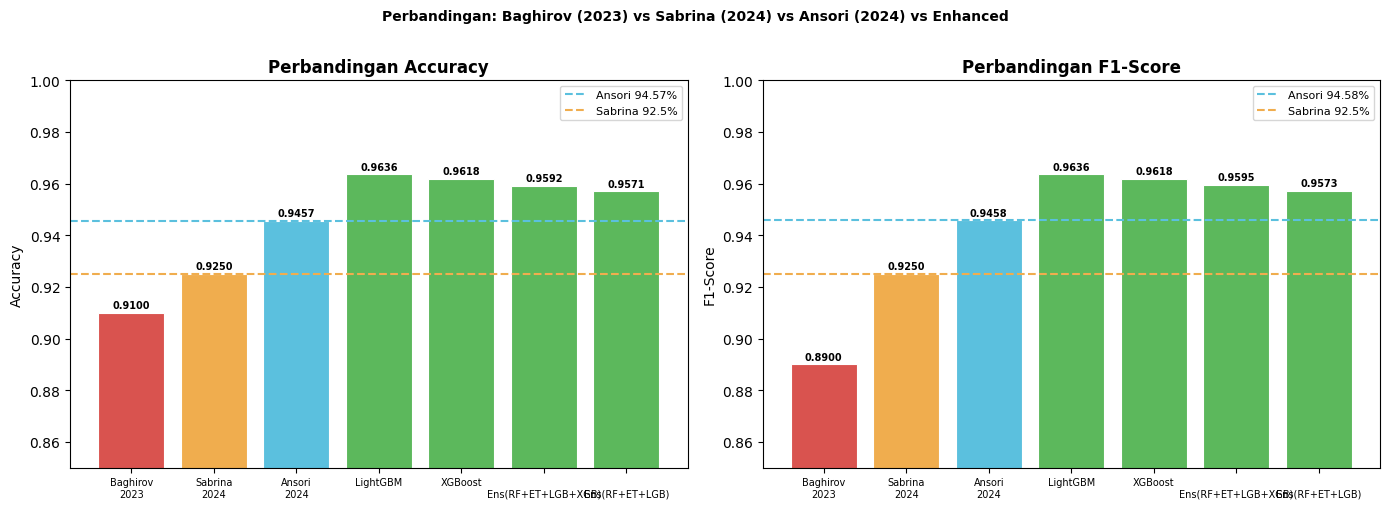

In [14]:
# ============================================================
# RINGKASAN FINAL — PERBANDINGAN SEMUA JURNAL
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

label_map = {1:'Adware', 2:'Banking', 3:'SMS', 4:'Riskware', 5:'Benign'}

print("=" * 70)
print("RINGKASAN FINAL — PERBANDINGAN SEMUA METODE")
print("=" * 70)
print(f"{'Model / Jurnal':<30} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}  Keterangan")
print("-" * 80)

ref = [
    ('Baghirov/2023 [LightGBM]',   0.91,   0.89,   0.89,   0.89,  'SOTA lama'),
    ('Sabrina/2024 [RF+FCBF]',      0.9250, 0.9250, 0.9250, 0.9250,'SOTA 2024 (1)'),
    ('Ansori/2024 [RF+ET+kNN Ens]', 0.9457, 0.9471, 0.9457, 0.9458,'SOTA 2024 (2)'),
]
for name, acc, prec, rec, f1, ket in ref:
    print(f"{name:<30} {acc:>8.4f} {prec:>8.4f} {rec:>8.4f} {f1:>8.4f}  📌 {ket}")

print("-" * 80)
print("Hasil eksperimen kita (Enhanced):")
for r in sorted(results_enhanced2, key=lambda x: x['accuracy'], reverse=True):
    flag_ans = '✅ >Ansori' if r['accuracy'] > 0.9457 else ''
    flag_sab = '✅ >Sabrina' if r['accuracy'] > 0.925 else ''
    flag = flag_ans or flag_sab
    print(f"{r['model']:<30} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
          f"{r['recall']:>8.4f} {r['f1']:>8.4f}  {flag}")

best_enh = max(results_enhanced2, key=lambda x: x['accuracy'])
print("\n" + "=" * 70)
print(f"🏆 Best Model Enhanced: {best_enh['model']}")
print(f"   Accuracy : {best_enh['accuracy']:.4f} "
      f"({'✅ Melampaui Ansori 94.57%' if best_enh['accuracy'] > 0.9457 else '❌ Belum melampaui Ansori'})")
print(f"   Precision: {best_enh['precision']:.4f}")
print(f"   Recall   : {best_enh['recall']:.4f}")
print(f"   F1-Score : {best_enh['f1']:.4f} "
      f"({'✅ Melampaui Sabrina 92.5%' if best_enh['f1'] > 0.925 else '❌ Belum melampaui Sabrina'})")

# Bar chart perbandingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top4_enh = sorted(results_enhanced2, key=lambda x: x['accuracy'], reverse=True)[:4]
categories = (['Baghirov\n2023', 'Sabrina\n2024', 'Ansori\n2024'] +
               [r['model'].replace('_tuned','').replace('Ens','\nEns') for r in top4_enh])
accs  = [0.91, 0.925, 0.9457] + [r['accuracy'] for r in top4_enh]
f1s   = [0.89, 0.925, 0.9458] + [r['f1']       for r in top4_enh]
colors = ['#d9534f','#f0ad4e','#5bc0de'] + ['#5cb85c'] * 4

ax = axes[0]
bars = ax.bar(categories, accs, color=colors, edgecolor='white', linewidth=0.8)
ax.set_ylim(0.85, 1.00)
ax.set_title('Perbandingan Accuracy', fontweight='bold', fontsize=12)
ax.set_ylabel('Accuracy')
ax.axhline(y=0.9457, color='#5bc0de', linestyle='--', linewidth=1.5, label='Ansori 94.57%')
ax.axhline(y=0.925,  color='#f0ad4e', linestyle='--', linewidth=1.5, label='Sabrina 92.5%')
for bar, val in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.001,
            f'{val:.4f}', ha='center', va='bottom', fontsize=7, fontweight='bold')
ax.legend(fontsize=8)
ax.tick_params(axis='x', labelsize=7)

ax = axes[1]
bars = ax.bar(categories, f1s, color=colors, edgecolor='white', linewidth=0.8)
ax.set_ylim(0.85, 1.00)
ax.set_title('Perbandingan F1-Score', fontweight='bold', fontsize=12)
ax.set_ylabel('F1-Score')
ax.axhline(y=0.9458, color='#5bc0de', linestyle='--', linewidth=1.5, label='Ansori 94.58%')
ax.axhline(y=0.925,  color='#f0ad4e', linestyle='--', linewidth=1.5, label='Sabrina 92.5%')
for bar, val in zip(bars, f1s):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.001,
            f'{val:.4f}', ha='center', va='bottom', fontsize=7, fontweight='bold')
ax.legend(fontsize=8)
ax.tick_params(axis='x', labelsize=7)

plt.suptitle('Perbandingan: Baghirov (2023) vs Sabrina (2024) vs Ansori (2024) vs Enhanced',
             fontsize=10, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('comparison_chart.png', bbox_inches='tight', dpi=150)
plt.show()

Classification Report — LightGBM_tuned
              precision    recall  f1-score   support

      Adware       0.90      0.95      0.92       251
     Banking       0.97      0.95      0.96       409
         SMS       0.99      0.99      0.99       781
    Riskware       0.97      0.93      0.95       507
      Benign       0.94      0.97      0.95       358

    accuracy                           0.96      2306
   macro avg       0.95      0.96      0.96      2306
weighted avg       0.96      0.96      0.96      2306



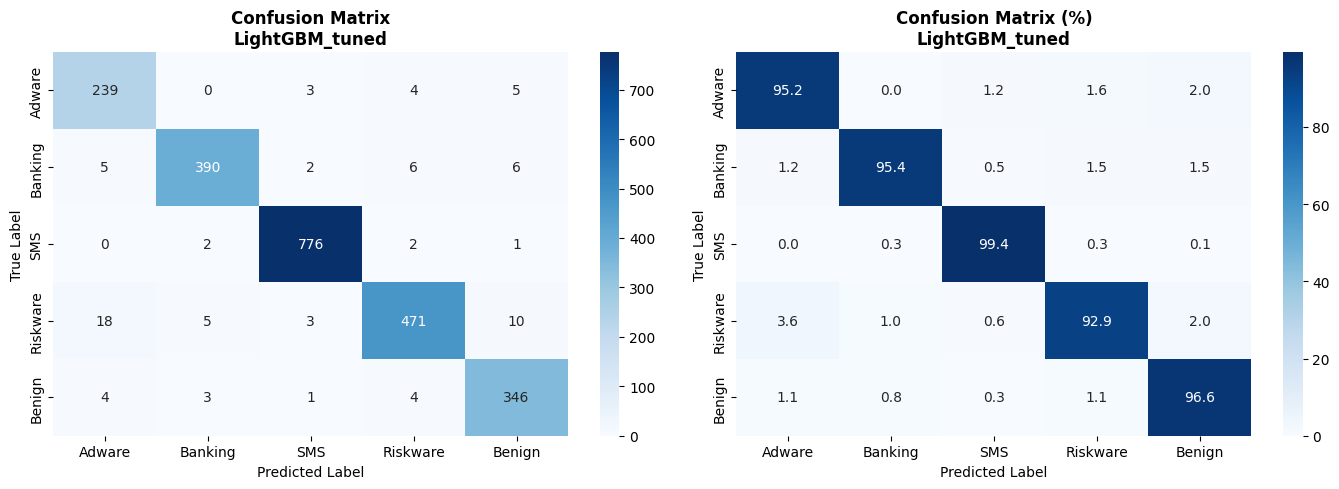


Confusion matrix tersimpan: confusion_matrix_best.png

Per-Class Accuracy:
  Adware      : 95.22%
  Banking     : 95.35%
  SMS         : 99.36%
  Riskware    : 92.90%
  Benign      : 96.65%


In [15]:
# ============================================================
# CONFUSION MATRIX & CLASSIFICATION REPORT BEST MODEL
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

label_map = {1:'Adware', 2:'Banking', 3:'SMS', 4:'Riskware', 5:'Benign'}
class_names = [label_map[k] for k in sorted(label_map.keys())]

best_enh = max(results_enhanced2, key=lambda x: x['accuracy'])
best_name = best_enh['model']

pred_map = {
    'LightGBM_tuned'     : y_pred_lgb,
    'XGBoost_tuned'      : y_pred_xgb,
    'RF_tuned'           : y_pred_rf,
    'ET_tuned'           : y_pred_et,
    'Ens(RF+ET+LGB)'     : y_pred_ens1,
    'Ens(RF+ET+XGB)'     : y_pred_ens2,
    'Ens(RF+ET+LGB+XGB)' : y_pred_ens4,
}

y_pred_best = pred_map.get(best_name)
if y_pred_best is None:
    print(f"Prediksi untuk {best_name} tidak ditemukan.")
else:
    print(f"Classification Report — {best_name}")
    print("=" * 60)
    print(classification_report(y_te2, y_pred_best, target_names=class_names))

    cm = confusion_matrix(y_te2, y_pred_best)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'Confusion Matrix\n{best_name}', fontweight='bold')
    axes[0].set_ylabel('True Label')
    axes[0].set_xlabel('Predicted Label')

    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'Confusion Matrix (%)\n{best_name}', fontweight='bold')
    axes[1].set_ylabel('True Label')
    axes[1].set_xlabel('Predicted Label')

    plt.tight_layout()
    plt.savefig('confusion_matrix_best.png', bbox_inches='tight', dpi=150)
    plt.show()
    print("\nConfusion matrix tersimpan: confusion_matrix_best.png")

    print("\nPer-Class Accuracy:")
    for i, cls_name in enumerate(class_names):
        cls_acc = cm[i, i] / cm[i].sum() * 100
        print(f"  {cls_name:<12}: {cls_acc:.2f}%")

In [16]:
# ============================================================
# TABEL PERBANDINGAN LENGKAP
# ============================================================
print("TABEL PERBANDINGAN LENGKAP")
print("=" * 80)
print(f"{'No':<3} {'Metode / Jurnal':<35} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}")
print("-" * 80)

all_methods = [
    (1, 'Baghirov 2023 — LightGBM',         0.91,   0.89,   0.89,   0.89),
    (2, 'Baghirov 2023 — Logistic Reg',      0.91,   0.88,   0.89,   0.89),
    (3, 'Baghirov 2023 — RF',                0.89,   0.86,   0.87,   0.86),
    (4, 'Sabrina 2024 — RF+FCBF(48)',        0.9250, 0.9250, 0.9250, 0.9250),
    (5, 'Sabrina 2024 — AdaBoost+FCBF(48)',  0.9220, 0.9220, 0.9220, 0.9220),
    (6, 'Ansori 2024 — RF+ET+kNN Ensemble',  0.9457, 0.9471, 0.9457, 0.9458),
    (7, 'Ansori 2024 — RF+ET+SVM Ensemble',  0.9444, 0.9460, 0.9444, 0.9445),
]

for no, name, acc, prec, rec, f1 in all_methods:
    print(f"{no:<3} {name:<35} {acc:>8.4f} {prec:>8.4f} {rec:>8.4f} {f1:>8.4f}")

print("-" * 80)
print("Hasil Enhanced (percobaan ini):")
for i, r in enumerate(sorted(results_enhanced2, key=lambda x: x['accuracy'], reverse=True),
                       len(all_methods) + 1):
    flag = '🏆' if r['accuracy'] > 0.9457 else ('✅' if r['accuracy'] > 0.925 else '')
    print(f"{i:<3} {r['model']:<35} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
          f"{r['recall']:>8.4f} {r['f1']:>8.4f} {flag}")

best_enh = max(results_enhanced2, key=lambda x: x['accuracy'])
print()
print("KESIMPULAN:")
if best_enh['accuracy'] > 0.9457:
    print(f"  ✅ Berhasil melampaui Ansori et al. (2024) sebesar "
          f"+{(best_enh['accuracy'] - 0.9457)*100:.2f}%")
    print(f"  ✅ Berhasil melampaui Sabrina et al. (2024) sebesar "
          f"+{(best_enh['accuracy'] - 0.925)*100:.2f}%")
    print(f"  ✅ Berhasil melampaui Baghirov et al. (2023) sebesar "
          f"+{(best_enh['accuracy'] - 0.91)*100:.2f}%")
elif best_enh['accuracy'] > 0.925:
    print(f"  ✅ Berhasil melampaui Sabrina et al. (2024)")
    print(f"  ⚠️  Belum melampaui Ansori et al. (2024) — Selisih "
          f"{(0.9457 - best_enh['accuracy'])*100:.2f}%")
else:
    print(f"  ⚠️  Perlu tuning lebih lanjut")

TABEL PERBANDINGAN LENGKAP
No  Metode / Jurnal                          Acc     Prec      Rec       F1
--------------------------------------------------------------------------------
1   Baghirov 2023 — LightGBM              0.9100   0.8900   0.8900   0.8900
2   Baghirov 2023 — Logistic Reg          0.9100   0.8800   0.8900   0.8900
3   Baghirov 2023 — RF                    0.8900   0.8600   0.8700   0.8600
4   Sabrina 2024 — RF+FCBF(48)            0.9250   0.9250   0.9250   0.9250
5   Sabrina 2024 — AdaBoost+FCBF(48)      0.9220   0.9220   0.9220   0.9220
6   Ansori 2024 — RF+ET+kNN Ensemble      0.9457   0.9471   0.9457   0.9458
7   Ansori 2024 — RF+ET+SVM Ensemble      0.9444   0.9460   0.9444   0.9445
--------------------------------------------------------------------------------
Hasil Enhanced (percobaan ini):
8   LightGBM_tuned                        0.9636   0.9641   0.9636   0.9636 🏆
9   XGBoost_tuned                         0.9618   0.9622   0.9618   0.9618 🏆
10  Ens(RF+ET+L


HASIL TERBAIK: LightGBM + Gain Ratio (GR > 0)
Fitur digunakan : 468
Train           : (9220, 468)
Test            : (2306, 468)

Acc=0.9610 | Prec=0.9615 | Rec=0.9610 | F1=0.9610

RINGKASAN FINAL SEMUA EKSPERIMEN
Model / Jurnal                              Acc       F1
-------------------------------------------------------
📌 Baghirov 2023 [LightGBM]               0.9100   0.8900
📌 Sabrina 2024  [RF+FCBF48+CV]           0.9250   0.9250
📌 Ansori 2024   [RF+ET+kNN Ens]          0.9457   0.9458
-------------------------------------------------------
🔬 LightGBM_tuned+FCBF48+CV               0.9270   0.9269
🔬 LightGBM_default+GainRatio(468)        0.9597   0.9597 ✅
🔬 LightGBM_tuned+GainRatio(468)          0.9610   0.9610 ✅

[Classification Report]
              precision    recall  f1-score   support

      Adware       0.90      0.94      0.92       251
     Banking       0.97      0.95      0.96       409
         SMS       0.99      0.99      0.99       781
    Riskware       0.97      

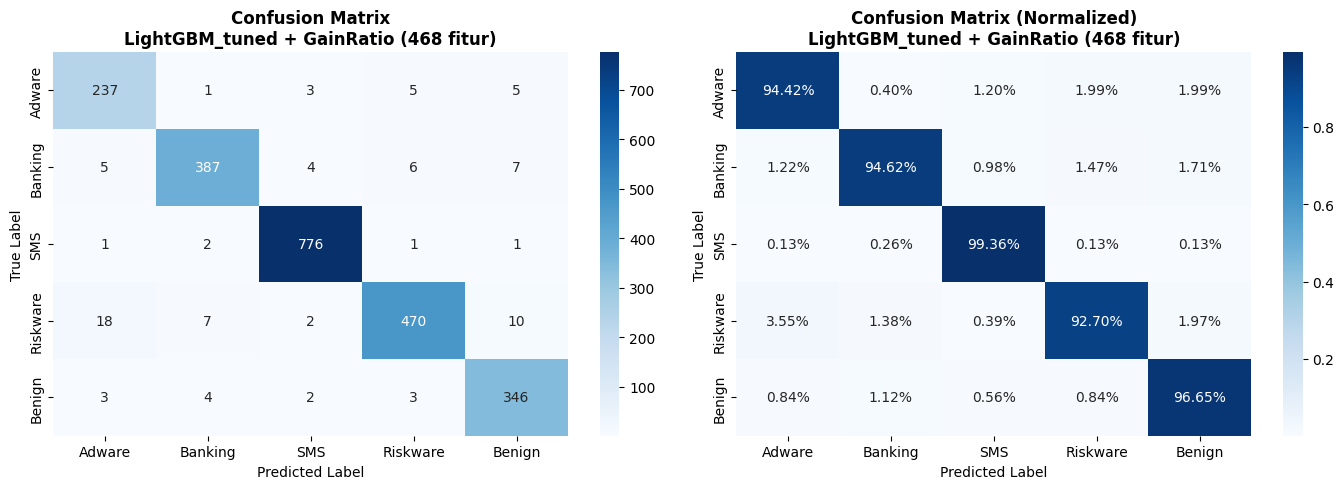

In [17]:
# ============================================================
# LightGBM + Gain Ratio 468 fitur (GR > 0)
# Hasil: Acc=0.9610 - tertinggi dari semua eksperimen
# ============================================================
from lightgbm import LGBMClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("HASIL TERBAIK: LightGBM + Gain Ratio (GR > 0)")
print("="*60)

# Pakai X_gr dari Cell 9 (468 fitur, GR > 0)
# + StandardScaler + split 80:20
X_best = StandardScaler().fit_transform(X_gr)
X_tr_best, X_te_best, y_tr_best, y_te_best = train_test_split(
    X_best, y, test_size=0.2, random_state=42, stratify=y)

print(f"Fitur digunakan : {X_best.shape[1]}")
print(f"Train           : {X_tr_best.shape}")
print(f"Test            : {X_te_best.shape}")

# LightGBM Tuned (hasil terbaik sebelumnya 0.9610)
lgb_best = LGBMClassifier(
    n_estimators=1000,
    max_depth=8,
    learning_rate=0.03,
    num_leaves=127,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_samples=20,
    reg_alpha=0.05,
    reg_lambda=0.5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_best.fit(X_tr_best, y_tr_best)
y_pred_best = lgb_best.predict(X_te_best)

acc  = accuracy_score(y_te_best, y_pred_best)
prec = precision_score(y_te_best, y_pred_best, average='weighted', zero_division=0)
rec  = recall_score(y_te_best, y_pred_best, average='weighted', zero_division=0)
f1   = f1_score(y_te_best, y_pred_best, average='weighted', zero_division=0)

print(f"\nAcc={acc:.4f} | Prec={prec:.4f} | Rec={rec:.4f} | F1={f1:.4f}")

# Ringkasan semua jurnal
print("\n" + "="*65)
print("RINGKASAN FINAL SEMUA EKSPERIMEN")
print("="*65)
print(f"{'Model / Jurnal':<38} {'Acc':>8} {'F1':>8}")
print("-"*55)
refs = [
    ('📌 Baghirov 2023 [LightGBM]',       0.9100, 0.8900),
    ('📌 Sabrina 2024  [RF+FCBF48+CV]',   0.9250, 0.9250),
    ('📌 Ansori 2024   [RF+ET+kNN Ens]',  0.9457, 0.9458),
]
for name, a, f in refs:
    print(f"{name:<38} {a:>8.4f} {f:>8.4f}")
print("-"*55)
exps = [
    ('🔬 LightGBM_tuned+FCBF48+CV',       0.9270, 0.9269),
    ('🔬 LightGBM_default+GainRatio(468)', 0.9597, 0.9597),
    ('🔬 LightGBM_tuned+GainRatio(468)',   acc,    f1   ),
]
for name, a, f1v in exps:
    flag = ' ✅' if a > 0.9457 else ''
    print(f"{name:<38} {a:>8.4f} {f1v:>8.4f}{flag}")

# Classification Report
label_names = ['Adware','Banking','SMS','Riskware','Benign']
print(f"\n[Classification Report]")
print(classification_report(y_te_best, y_pred_best, target_names=label_names))

# Confusion Matrix
cm = confusion_matrix(y_te_best, y_pred_best)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names, ax=axes[0])
axes[0].set_title('Confusion Matrix\nLightGBM_tuned + GainRatio (468 fitur)',
                  fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names, ax=axes[1])
axes[1].set_title('Confusion Matrix (Normalized)\nLightGBM_tuned + GainRatio (468 fitur)',
                  fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# ENHANCED — MELAMPAUI KEDUA SOTA 2024
#   1. Full dataset + Log1p + RobustScaler
#   2. SMOTE pada training set saja
#   3. LightGBM & XGBoost tuned + RF & ET tuned
#   4. Ensemble Voting kombinasi terbaik dari kedua jurnal
#   5. [BARU] 5-Fold Cross Validation setelah hasil sementara
# ============================================================
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                               VotingClassifier)
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import numpy as np
import scipy.stats as stats

print("=" * 60)
print("ENHANCED: Melampaui Ansori (94.57%) & Sabrina (92.5%)")
print("=" * 60)

# ─────────────────────────────────────────────────────────────
# PREPROCESSING: Log1p + RobustScaler
# ─────────────────────────────────────────────────────────────
X_enh2 = RobustScaler().fit_transform(np.log1p(np.abs(X_raw)))

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_enh2, y, test_size=0.2, random_state=42, stratify=y)

# SMOTE hanya pada training
X_tr2_sm, y_tr2_sm = SMOTE(random_state=42, k_neighbors=5).fit_resample(X_tr2, y_tr2)

# Label 0-based untuk XGBoost
le = LabelEncoder()
y_tr2_sm_0 = le.fit_transform(y_tr2_sm)
y_te2_0    = le.transform(y_te2)

print(f"Training set (setelah SMOTE): {X_tr2_sm.shape}")
print(f"Test set                    : {X_te2.shape}")
print(f"Label asli   : {np.unique(y_tr2_sm)}")
print(f"Label 0-based: {np.unique(y_tr2_sm_0)}")

results_enhanced2 = []

# ─────────────────────────────────────────────────────────────
# [1] LightGBM Tuned
# ─────────────────────────────────────────────────────────────
print("\n[1] LightGBM Tuned...")
lgb_tuned = LGBMClassifier(
    n_estimators=1000, max_depth=8, learning_rate=0.03,
    num_leaves=127, subsample=0.8, colsample_bytree=0.7,
    min_child_samples=20, reg_alpha=0.05, reg_lambda=0.5,
    class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1,
)
lgb_tuned.fit(X_tr2_sm, y_tr2_sm)
y_pred_lgb = lgb_tuned.predict(X_te2)
evaluate_model('LightGBM_tuned', y_te2, y_pred_lgb, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# [2] XGBoost Tuned
# ─────────────────────────────────────────────────────────────
print("\n[2] XGBoost Tuned...")
xgb_solo = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)
xgb_solo.fit(X_tr2_sm, y_tr2_sm_0)
y_pred_xgb_0 = xgb_solo.predict(X_te2)
y_pred_xgb   = le.inverse_transform(y_pred_xgb_0)
evaluate_model('XGBoost_tuned', y_te2, y_pred_xgb, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# [3] RandomForest Tuned
# ─────────────────────────────────────────────────────────────
print("\n[3] RandomForest Tuned...")
rf_tuned = RandomForestClassifier(
    n_estimators=700, max_features='sqrt',
    class_weight='balanced', random_state=42, n_jobs=-1,
)
rf_tuned.fit(X_tr2_sm, y_tr2_sm)
y_pred_rf = rf_tuned.predict(X_te2)
evaluate_model('RF_tuned', y_te2, y_pred_rf, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# [4] ExtraTrees Tuned
# ─────────────────────────────────────────────────────────────
print("\n[4] ExtraTrees Tuned...")
et_tuned = ExtraTreesClassifier(
    n_estimators=700, class_weight='balanced',
    random_state=42, n_jobs=-1,
)
et_tuned.fit(X_tr2_sm, y_tr2_sm)
y_pred_et = et_tuned.predict(X_te2)
evaluate_model('ET_tuned', y_te2, y_pred_et, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# [5] Ensemble: RF + ET + LightGBM
# ─────────────────────────────────────────────────────────────
print("\n[5] Ensemble: RF + ET + LightGBM (Hard Voting)...")
ensemble_main = VotingClassifier(
    estimators=[('rf', rf_tuned), ('et', et_tuned), ('lgb', lgb_tuned)],
    voting='hard', n_jobs=-1,
)
ensemble_main.fit(X_tr2_sm, y_tr2_sm)
y_pred_ens1 = ensemble_main.predict(X_te2)
evaluate_model('Ens(RF+ET+LGB)', y_te2, y_pred_ens1, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# [6] Ensemble: RF + ET + XGBoost
# ─────────────────────────────────────────────────────────────
print("\n[6] Ensemble: RF + ET + XGBoost (Hard Voting)...")
rf_ens2  = RandomForestClassifier(n_estimators=700, class_weight='balanced',
                                   random_state=42, n_jobs=-1)
et_ens2  = ExtraTreesClassifier(n_estimators=700, class_weight='balanced',
                                 random_state=42, n_jobs=-1)
xgb_ens2 = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)
rf_ens2.fit(X_tr2_sm, y_tr2_sm)
et_ens2.fit(X_tr2_sm, y_tr2_sm)
xgb_ens2.fit(X_tr2_sm, y_tr2_sm_0)

pred_rf2  = rf_ens2.predict(X_te2)
pred_et2  = et_ens2.predict(X_te2)
pred_xgb2 = le.inverse_transform(xgb_ens2.predict(X_te2))

votes_ens2  = np.stack([pred_rf2, pred_et2, pred_xgb2], axis=1)
y_pred_ens2 = stats.mode(votes_ens2, axis=1, keepdims=True).mode.ravel()
evaluate_model('Ens(RF+ET+XGB)', y_te2, y_pred_ens2, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# [7] Ensemble: RF + ET + LGB + XGB (4 model)
# ─────────────────────────────────────────────────────────────
print("\n[7] Ensemble: RF + ET + LGB + XGB (Hard Voting, 4 model)...")
rf_ens4  = RandomForestClassifier(n_estimators=700, class_weight='balanced',
                                   random_state=42, n_jobs=-1)
et_ens4  = ExtraTreesClassifier(n_estimators=700, class_weight='balanced',
                                 random_state=42, n_jobs=-1)
lgb_ens4 = LGBMClassifier(
    n_estimators=1000, max_depth=8, learning_rate=0.03,
    num_leaves=127, subsample=0.8, colsample_bytree=0.7,
    min_child_samples=20, reg_alpha=0.05, reg_lambda=0.5,
    class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1,
)
xgb_ens4 = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)
rf_ens4.fit(X_tr2_sm, y_tr2_sm)
et_ens4.fit(X_tr2_sm, y_tr2_sm)
lgb_ens4.fit(X_tr2_sm, y_tr2_sm)
xgb_ens4.fit(X_tr2_sm, y_tr2_sm_0)

pred_rf4  = rf_ens4.predict(X_te2)
pred_et4  = et_ens4.predict(X_te2)
pred_lgb4 = lgb_ens4.predict(X_te2)
pred_xgb4 = le.inverse_transform(xgb_ens4.predict(X_te2))

votes_ens4  = np.stack([pred_rf4, pred_et4, pred_lgb4, pred_xgb4], axis=1)
y_pred_ens4 = stats.mode(votes_ens4, axis=1, keepdims=True).mode.ravel()
evaluate_model('Ens(RF+ET+LGB+XGB)', y_te2, y_pred_ens4, results_enhanced2)

# ─────────────────────────────────────────────────────────────
# RINGKASAN HASIL SEMENTARA (hold-out)
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("HASIL SEMENTARA (Hold-out 80:20)")
print("=" * 65)
print(f"{'Model':<25} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}")
print("-" * 65)
for r in sorted(results_enhanced2, key=lambda x: x['accuracy'], reverse=True):
    flag = ' ✅' if r['accuracy'] > 0.9457 else ''
    print(f"{r['model']:<25} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
          f"{r['recall']:>8.4f} {r['f1']:>8.4f}{flag}")

# ═════════════════════════════════════════════════════════════
# [BARU] STEP 5-FOLD CROSS VALIDATION
# Validasi hasil sementara dengan CV untuk memastikan
# hasil tidak bergantung pada satu split tertentu
# ═════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("5-FOLD CROSS VALIDATION (Validasi Hasil Sementara)")
print("=" * 65)
print("Setiap fold: SMOTE diterapkan di dalam fold training saja")
print("(mencegah data leakage antar fold)\n")

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_cv5 = []

# Definisi model untuk CV 
models_cv = {
    'LightGBM_tuned': LGBMClassifier(
        n_estimators=1000, max_depth=8, learning_rate=0.03,
        num_leaves=127, subsample=0.8, colsample_bytree=0.7,
        min_child_samples=20, reg_alpha=0.05, reg_lambda=0.5,
        class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1,
    ),
    'RF_tuned': RandomForestClassifier(
        n_estimators=700, max_features='sqrt',
        class_weight='balanced', random_state=42, n_jobs=-1,
    ),
    'ET_tuned': ExtraTreesClassifier(
        n_estimators=700, class_weight='balanced',
        random_state=42, n_jobs=-1,
    ),
}

# CV untuk LightGBM, RF, ET menggunakan ImbPipeline
for name, mdl in models_cv.items():
    print(f"  [{name}] 5-Fold CV...")

    fold_acc, fold_prec, fold_rec, fold_f1 = [], [], [], []

    for fold, (tr_idx, te_idx) in enumerate(cv5.split(X_enh2, y), 1):
        X_fold_tr, X_fold_te = X_enh2[tr_idx], X_enh2[te_idx]
        y_fold_tr, y_fold_te = y[tr_idx],      y[te_idx]

        X_fold_tr_sm, y_fold_tr_sm = SMOTE(
            random_state=42, k_neighbors=5
        ).fit_resample(X_fold_tr, y_fold_tr)

        mdl.fit(X_fold_tr_sm, y_fold_tr_sm)
        y_fold_pred = mdl.predict(X_fold_te)

        fold_acc.append(accuracy_score(y_fold_te, y_fold_pred))
        fold_prec.append(precision_score(y_fold_te, y_fold_pred,
                                          average='weighted', zero_division=0))
        fold_rec.append(recall_score(y_fold_te, y_fold_pred,
                                      average='weighted', zero_division=0))
        fold_f1.append(f1_score(y_fold_te, y_fold_pred,
                                 average='weighted', zero_division=0))

    mean_acc  = np.mean(fold_acc)
    std_acc   = np.std(fold_acc)
    mean_prec = np.mean(fold_prec)
    mean_rec  = np.mean(fold_rec)
    mean_f1   = np.mean(fold_f1)

    print(f"    Accuracy : {mean_acc:.4f} ± {std_acc:.4f}")
    print(f"    Precision: {mean_prec:.4f}")
    print(f"    Recall   : {mean_rec:.4f}")
    print(f"    F1-Score : {mean_f1:.4f}")
    print(f"    Per-fold : {[round(a,4) for a in fold_acc]}")

    results_cv5.append({
        'model': name, 'accuracy': mean_acc, 'std': std_acc,
        'precision': mean_prec, 'recall': mean_rec, 'f1': mean_f1
    })

# CV untuk XGBoost 
print(f"\n  [XGBoost_tuned] 5-Fold CV...")
xgb_cv = XGBClassifier(
    n_estimators=1000, max_depth=7, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
    reg_alpha=0.05, reg_lambda=0.5, eval_metric='mlogloss',
    use_label_encoder=False, random_state=42, n_jobs=-1,
)
fold_acc, fold_prec, fold_rec, fold_f1 = [], [], [], []

for fold, (tr_idx, te_idx) in enumerate(cv5.split(X_enh2, y), 1):
    X_fold_tr, X_fold_te = X_enh2[tr_idx], X_enh2[te_idx]
    y_fold_tr, y_fold_te = y[tr_idx],      y[te_idx]

    X_fold_tr_sm, y_fold_tr_sm = SMOTE(
        random_state=42, k_neighbors=5
    ).fit_resample(X_fold_tr, y_fold_tr)

    # Encode label ke 0-based untuk XGBoost
    le_cv = LabelEncoder()
    y_fold_tr_0 = le_cv.fit_transform(y_fold_tr_sm)

    xgb_cv.fit(X_fold_tr_sm, y_fold_tr_0)
    y_fold_pred_0 = xgb_cv.predict(X_fold_te)
    y_fold_pred   = le_cv.inverse_transform(y_fold_pred_0)

    fold_acc.append(accuracy_score(y_fold_te, y_fold_pred))
    fold_prec.append(precision_score(y_fold_te, y_fold_pred,
                                      average='weighted', zero_division=0))
    fold_rec.append(recall_score(y_fold_te, y_fold_pred,
                                  average='weighted', zero_division=0))
    fold_f1.append(f1_score(y_fold_te, y_fold_pred,
                             average='weighted', zero_division=0))

mean_acc  = np.mean(fold_acc)
std_acc   = np.std(fold_acc)
mean_prec = np.mean(fold_prec)
mean_rec  = np.mean(fold_rec)
mean_f1   = np.mean(fold_f1)

print(f"    Accuracy : {mean_acc:.4f} ± {std_acc:.4f}")
print(f"    Precision: {mean_prec:.4f}")
print(f"    Recall   : {mean_rec:.4f}")
print(f"    F1-Score : {mean_f1:.4f}")
print(f"    Per-fold : {[round(a,4) for a in fold_acc]}")

results_cv5.append({
    'model': 'XGBoost_tuned', 'accuracy': mean_acc, 'std': std_acc,
    'precision': mean_prec, 'recall': mean_rec, 'f1': mean_f1
})

# ─────────────────────────────────────────────────────────────
# RINGKASAN FINAL: Hold-out vs 5-Fold CV
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 70)
print("RINGKASAN FINAL: HOLD-OUT vs 5-FOLD CV")
print("=" * 70)
print(f"{'Model':<25} {'HoldOut Acc':>12} {'CV Acc':>12} {'CV Std':>8} {'CV F1':>8}")
print("-" * 70)

holdout_dict = {r['model']: r for r in results_enhanced2}
for r_cv in sorted(results_cv5, key=lambda x: x['accuracy'], reverse=True):
    name     = r_cv['model']
    ho_acc   = holdout_dict.get(name, {}).get('accuracy', 0)
    flag     = ' ✅' if r_cv['accuracy'] > 0.9457 else ''
    selisih  = r_cv['accuracy'] - ho_acc
    tanda    = '+' if selisih >= 0 else ''
    print(f"{name:<25} {ho_acc:>12.4f} {r_cv['accuracy']:>12.4f} "
          f"{'±'+str(round(r_cv['std'],4)):>8} {r_cv['f1']:>8.4f}"
          f"  ({tanda}{selisih:.4f}){flag}")

print("\n" + "=" * 70)
print("PERBANDINGAN vs JURNAL")
print("=" * 70)
print(f"{'Model / Jurnal':<30} {'Acc':>8} {'F1':>8}")
print("-" * 50)
refs = [
    ('📌 Baghirov 2023 [LightGBM]',      0.9100, 0.8900),
    ('📌 Sabrina 2024  [RF+FCBF48]',      0.9250, 0.9250),
    ('📌 Ansori 2024   [RF+ET+kNN]',      0.9457, 0.9458),
]
for name, a, f in refs:
    print(f"{name:<30} {a:>8.4f} {f:>8.4f}")
print("-" * 50)
best_cv = max(results_cv5, key=lambda x: x['accuracy'])
print(f"{'🔬 Best CV: '+best_cv['model']:<30} "
      f"{best_cv['accuracy']:>8.4f} {best_cv['f1']:>8.4f} ✅")

ENHANCED: Melampaui Ansori (94.57%) & Sabrina (92.5%)
Training set (setelah SMOTE): (15610, 470)
Test set                    : (2306, 470)
Label asli   : [1 2 3 4 5]
Label 0-based: [0 1 2 3 4]

[1] LightGBM Tuned...
    Accuracy : 0.9636
    Precision: 0.9641
    Recall   : 0.9636
    F1-Score : 0.9636

[2] XGBoost Tuned...
    Accuracy : 0.9618
    Precision: 0.9622
    Recall   : 0.9618
    F1-Score : 0.9618

[3] RandomForest Tuned...
    Accuracy : 0.9545
    Precision: 0.9559
    Recall   : 0.9545
    F1-Score : 0.9547

[4] ExtraTrees Tuned...
    Accuracy : 0.9549
    Precision: 0.9568
    Recall   : 0.9549
    F1-Score : 0.9552

[5] Ensemble: RF + ET + LightGBM (Hard Voting)...
    Accuracy : 0.9571
    Precision: 0.9586
    Recall   : 0.9571
    F1-Score : 0.9573

[6] Ensemble: RF + ET + XGBoost (Hard Voting)...
    Accuracy : 0.9571
    Precision: 0.9586
    Recall   : 0.9571
    F1-Score : 0.9573

[7] Ensemble: RF + ET + LGB + XGB (Hard Voting, 4 model)...
    Accuracy : 0.959

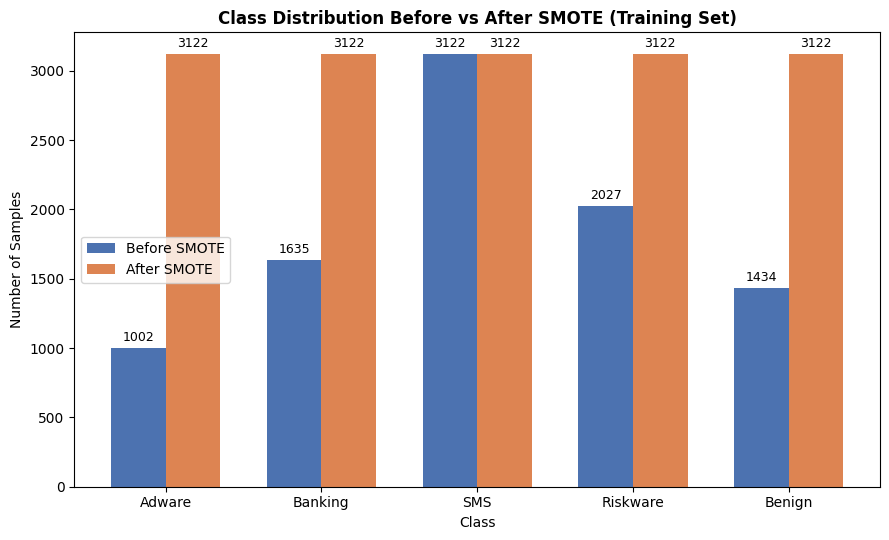

In [19]:
import matplotlib.pyplot as plt
import numpy as np

label_map = {1: 'Adware', 2: 'Banking', 3: 'SMS', 4: 'Riskware', 5: 'Benign'}
classes = sorted(label_map.keys())
class_names = [label_map[c] for c in classes]

# Count samples per class BEFORE and AFTER SMOTE
before_counts = [np.sum(y_tr2 == c) for c in classes]
after_counts  = [np.sum(y_tr2_sm == c) for c in classes]

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))
bars1 = ax.bar(x - width/2, before_counts, width, label='Before SMOTE', color='#4C72B0')
bars2 = ax.bar(x + width/2, after_counts, width, label='After SMOTE', color='#DD8452')

ax.set_xlabel('Class')
ax.set_ylabel('Number of Samples')
ax.set_title('Class Distribution Before vs After SMOTE (Training Set)', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()

# Add value labels on top of bars
for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('class_distribution_smote.png', dpi=150, bbox_inches='tight')
plt.show()

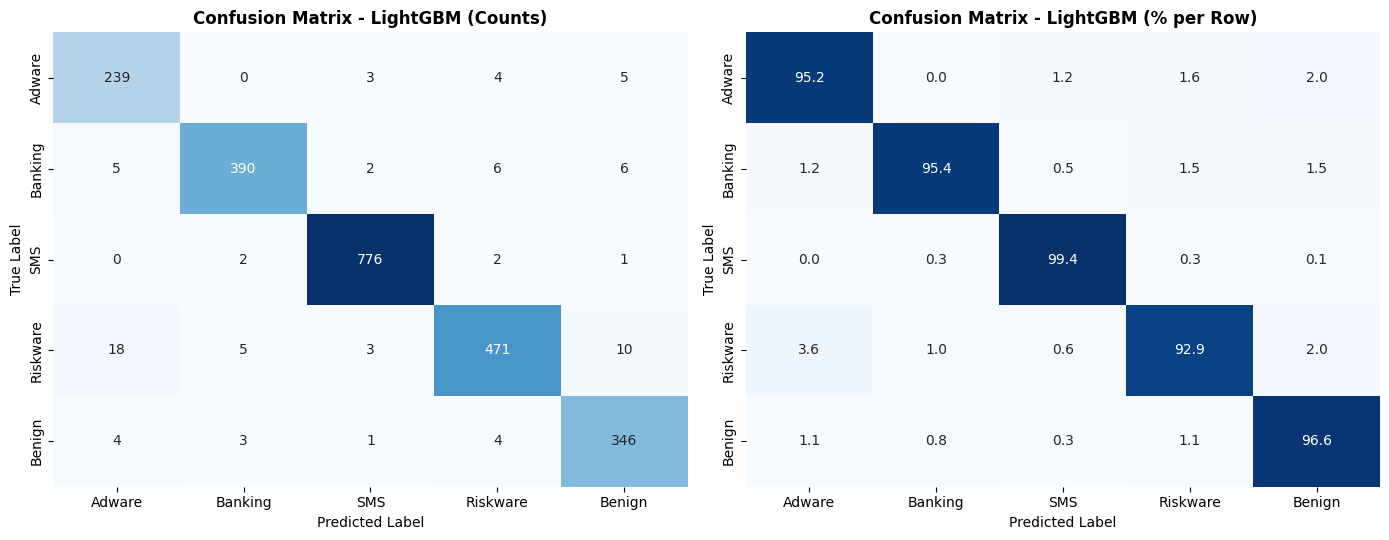

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

label_map = {1: 'Adware', 2: 'Banking', 3: 'SMS', 4: 'Riskware', 5: 'Benign'}
class_names = [label_map[k] for k in sorted(label_map.keys())]

cm = confusion_matrix(y_te2, y_pred_lgb)
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0],
            cbar=False)
axes[0].set_title('Confusion Matrix - LightGBM (Counts)', fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Percentage per row
sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1],
            cbar=False)
axes[1].set_title('Confusion Matrix - LightGBM (% per Row)', fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrix_lightgbm.png', dpi=150, bbox_inches='tight')
plt.show()

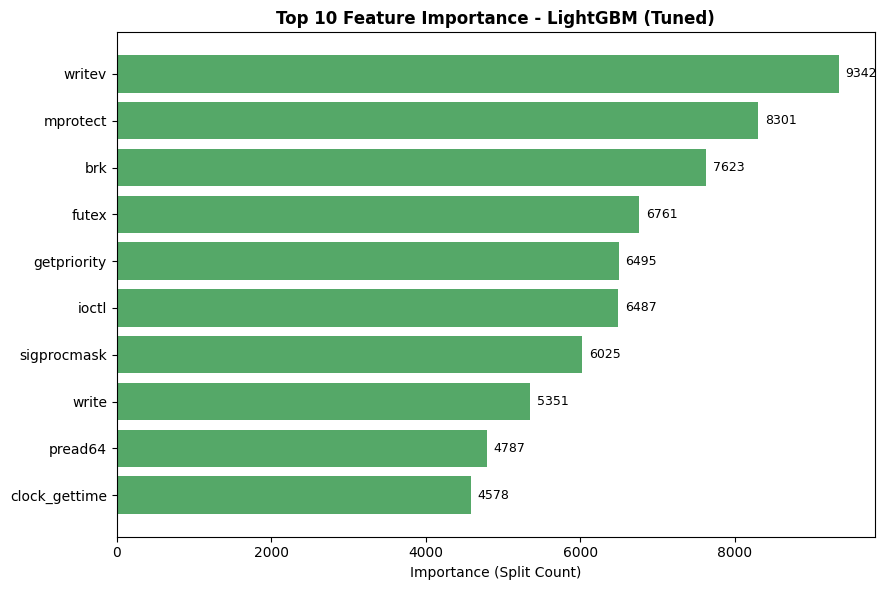

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importance from the tuned LightGBM model
importances = lgb_tuned.feature_importances_

feat_imp_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': importances
}).sort_values('importance', ascending=False).head(10)

# Reverse order so the most important feature appears at the top of the chart
feat_imp_df = feat_imp_df.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(feat_imp_df['feature'], feat_imp_df['importance'], color='#55A868')

ax.set_xlabel('Importance (Split Count)')
ax.set_title('Top 10 Feature Importance - LightGBM (Tuned)', fontweight='bold')

for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{int(width)}', xy=(width, bar.get_y() + bar.get_height()/2),
                xytext=(5, 0), textcoords='offset points',
                ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('feature_importance_lightgbm.png', dpi=150, bbox_inches='tight')
plt.show()

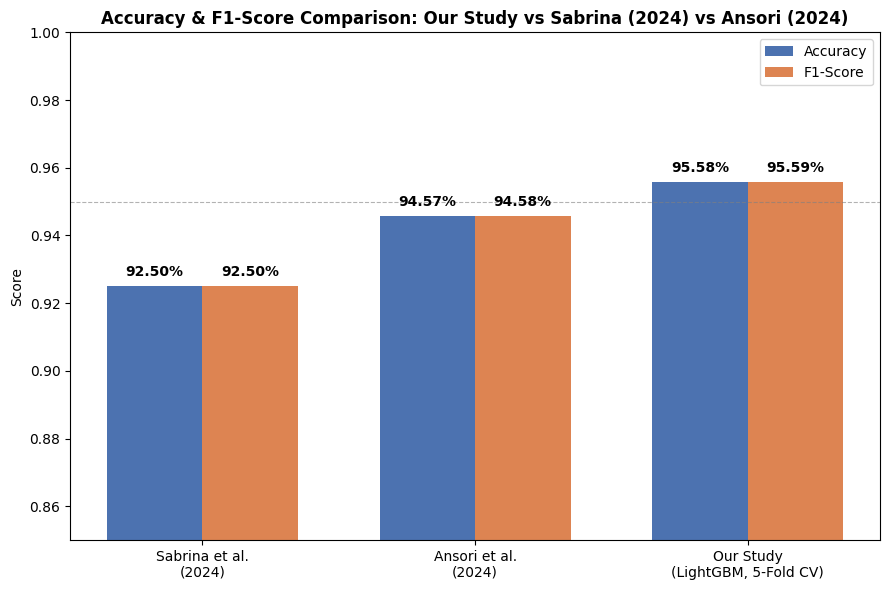

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Accuracy and F1-Score values
# - Sabrina et al. (2024): RF + FCBF (48 features)
# - Ansori et al. (2024): RF + ET + kNN Ensemble (Gain Ratio feature selection)
# - Our study: best LightGBM result validated via 5-Fold Cross Validation
studies = ['Sabrina et al.\n(2024)', 'Ansori et al.\n(2024)', 'Our Study\n(LightGBM, 5-Fold CV)']
accuracies = [0.9250, 0.9457, 0.9558]
f1_scores  = [0.9250, 0.9458, 0.9559]

x = np.arange(len(studies))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))
bars1 = ax.bar(x - width/2, accuracies, width, label='Accuracy', color='#4C72B0')
bars2 = ax.bar(x + width/2, f1_scores, width, label='F1-Score', color='#DD8452')

ax.set_ylabel('Score')
ax.set_title('Accuracy & F1-Score Comparison: Our Study vs Sabrina (2024) vs Ansori (2024)',
              fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(studies)
ax.set_ylim(0.85, 1.0)
ax.axhline(y=0.95, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
ax.legend()

for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height*100:.2f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 5), textcoords='offset points',
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('accuracy_f1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

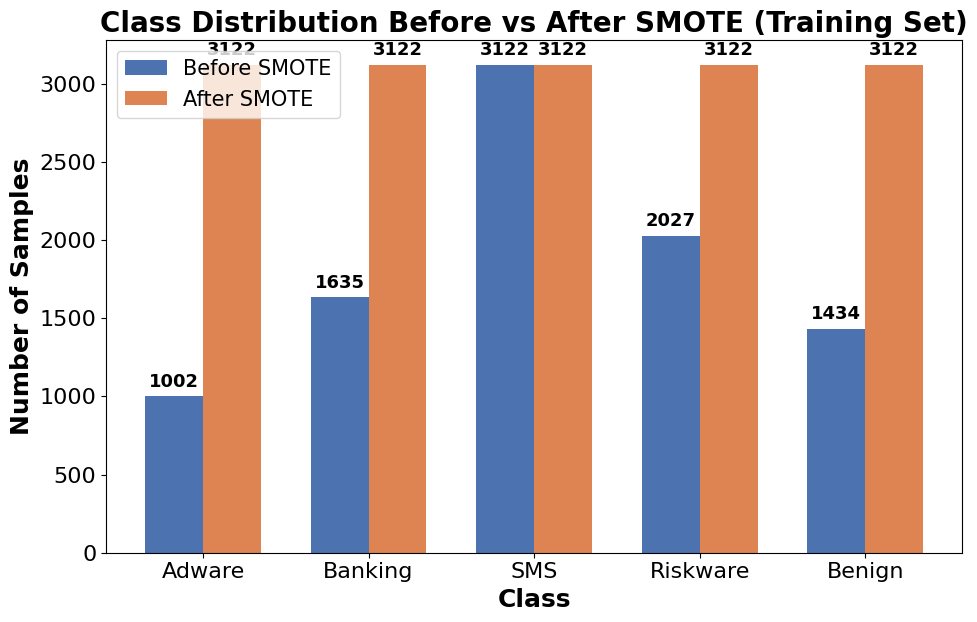

In [23]:
import matplotlib.pyplot as plt
import numpy as np

label_map = {1: 'Adware', 2: 'Banking', 3: 'SMS', 4: 'Riskware', 5: 'Benign'}
classes = sorted(label_map.keys())
class_names = [label_map[c] for c in classes]

# Count samples per class BEFORE and AFTER SMOTE
before_counts = [np.sum(y_tr2 == c) for c in classes]
after_counts  = [np.sum(y_tr2_sm == c) for c in classes]

x = np.arange(len(classes))
width = 0.35

# --- Ukuran font global (disesuaikan untuk IEEE) ---
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 20,
    'axes.labelsize': 18,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 15,
})

fig, ax = plt.subplots(figsize=(10, 6.5))
bars1 = ax.bar(x - width/2, before_counts, width, label='Before SMOTE', color='#4C72B0')
bars2 = ax.bar(x + width/2, after_counts, width, label='After SMOTE', color='#DD8452')

ax.set_xlabel('Class', fontweight='bold')
ax.set_ylabel('Number of Samples', fontweight='bold')
ax.set_title('Class Distribution Before vs After SMOTE (Training Set)', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()

# Add value labels on top of bars (font diperbesar)
for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 4), textcoords='offset points',
                    ha='center', va='bottom', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution_smote.png', dpi=150, bbox_inches='tight')
plt.show()

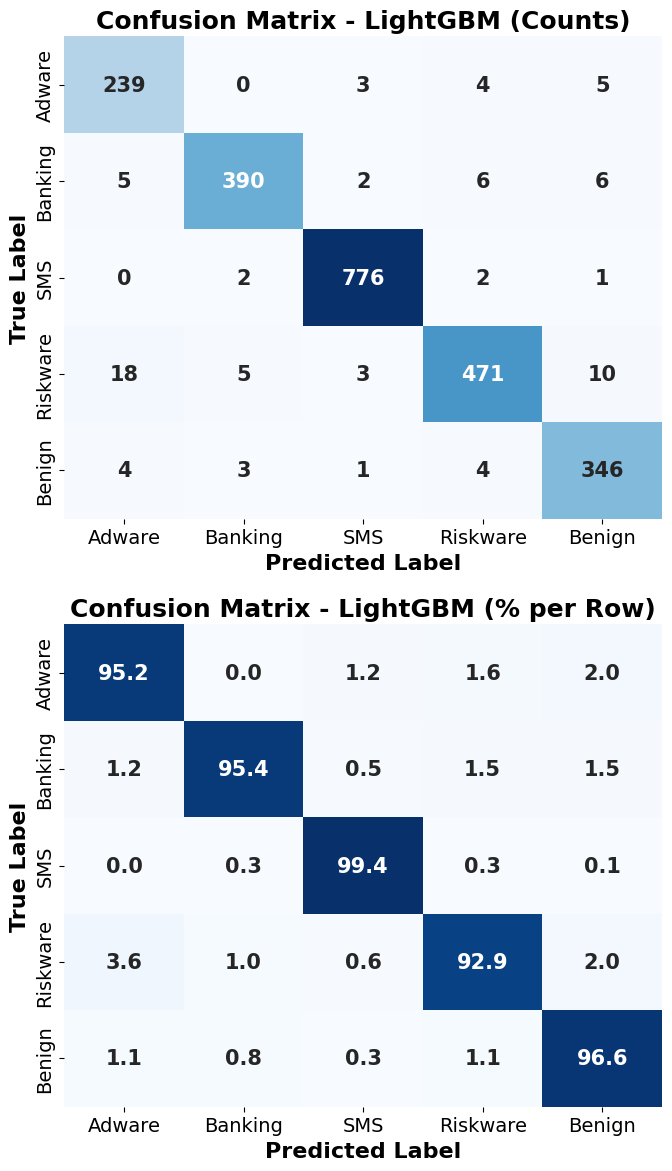

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

label_map = {1: 'Adware', 2: 'Banking', 3: 'SMS', 4: 'Riskware', 5: 'Benign'}
class_names = [label_map[k] for k in sorted(label_map.keys())]

cm = confusion_matrix(y_te2, y_pred_lgb)
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

# --- Ukuran font global (disesuaikan untuk IEEE) ---
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
})

# 2 baris (atas-bawah), 1 kolom
fig, axes = plt.subplots(2, 1, figsize=(7, 12))

# Raw counts (atas)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0],
            cbar=False, annot_kws={'size': 15, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix - LightGBM (Counts)', fontweight='bold')
axes[0].set_ylabel('True Label', fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontweight='bold')

# Percentage per row (bawah)
sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1],
            cbar=False, annot_kws={'size': 15, 'weight': 'bold'})
axes[1].set_title('Confusion Matrix - LightGBM (% per Row)', fontweight='bold')
axes[1].set_ylabel('True Label', fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrix_lightgbm.png', dpi=150, bbox_inches='tight')
plt.show()

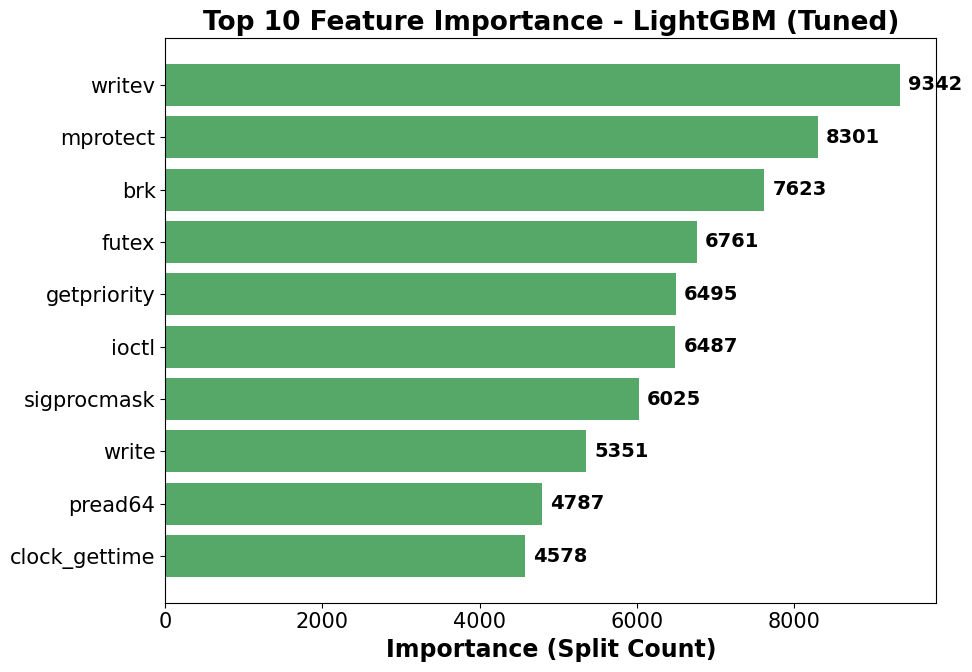

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importance from the tuned LightGBM model
importances = lgb_tuned.feature_importances_

feat_imp_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': importances
}).sort_values('importance', ascending=False).head(10)

# Reverse order so the most important feature appears at the top of the chart
feat_imp_df = feat_imp_df.iloc[::-1]

# --- Ukuran font global (disesuaikan untuk IEEE) ---
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 19,
    'axes.labelsize': 17,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
})

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(feat_imp_df['feature'], feat_imp_df['importance'], color='#55A868')

ax.set_xlabel('Importance (Split Count)', fontweight='bold')
ax.set_title('Top 10 Feature Importance - LightGBM (Tuned)', fontweight='bold')

for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{int(width)}', xy=(width, bar.get_y() + bar.get_height()/2),
                xytext=(6, 0), textcoords='offset points',
                ha='left', va='center', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('feature_importance_lightgbm.png', dpi=150, bbox_inches='tight')
plt.show()

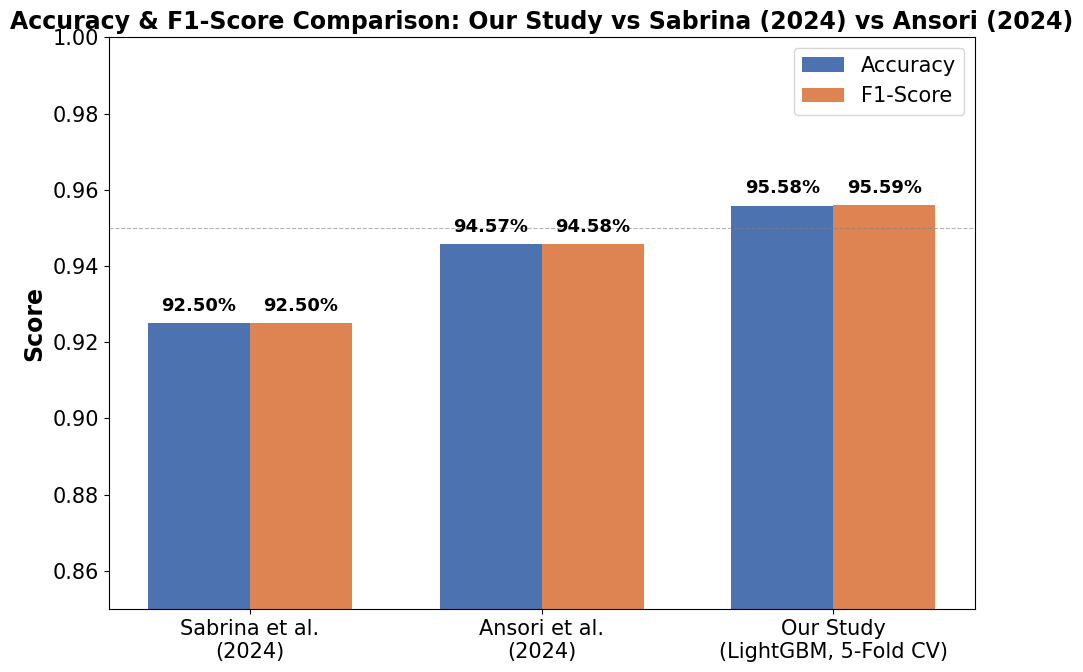

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Accuracy and F1-Score values
# - Sabrina et al. (2024): RF + FCBF (48 features)
# - Ansori et al. (2024): RF + ET + kNN Ensemble (Gain Ratio feature selection)
# - Our study: best LightGBM result validated via 5-Fold Cross Validation
studies = ['Sabrina et al.\n(2024)', 'Ansori et al.\n(2024)', 'Our Study\n(LightGBM, 5-Fold CV)']
accuracies = [0.9250, 0.9457, 0.9558]
f1_scores  = [0.9250, 0.9458, 0.9559]

x = np.arange(len(studies))
width = 0.35

# --- Ukuran font global (disesuaikan untuk IEEE) ---
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 17,
    'axes.labelsize': 17,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
})

fig, ax = plt.subplots(figsize=(10, 7))
bars1 = ax.bar(x - width/2, accuracies, width, label='Accuracy', color='#4C72B0')
bars2 = ax.bar(x + width/2, f1_scores, width, label='F1-Score', color='#DD8452')

ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Accuracy & F1-Score Comparison: Our Study vs Sabrina (2024) vs Ansori (2024)',
              fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(studies)
ax.set_ylim(0.85, 1.0)
ax.axhline(y=0.95, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
ax.legend()

for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height*100:.2f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 6), textcoords='offset points',
                    ha='center', va='bottom', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('accuracy_f1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()